In [146]:
# Lab 1 — Code 1: Installation

!pip install -q transformers pandas matplotlib

In [147]:
# Lab 1 — Code 2: Import Libraries


import pandas as pd

import re

import matplotlib.pyplot as plt

from transformers import AutoTokenizer

In [112]:
# Lab 1 – Code 3: Load Dataset
df = pd.read_excel("lahjti data_full.xlsx")
df["language"] = "ar"

print("عدد الجمل:", len(df))
print(df["dialect"].value_counts())
display(df.head(10))

عدد الجمل: 144
dialect
najdi      36
hijazi     36
qassimi    36
msa        36
Name: count, dtype: int64


,text,dialect,intent,customer_id,language
0,وش رصيدي الحين,najdi,balance,1,ar
1,كم باقي في حسابي,najdi,balance,2,ar
2,ابي اعرف كم عندي بالحساب,najdi,balance,3,ar
3,ودي اشوف رصيدي,najdi,balance,4,ar
4,كم فلوسي في الحساب,najdi,balance,5,ar
5,قل لي وش باقي بحسابي,najdi,balance,6,ar
6,ابي احول خمسمية لأخوي,najdi,transfer,7,ar
7,حول لأبوي ألف ريال,najdi,transfer,1,ar
8,ودي ارسل مبلغ لصاحبي,najdi,transfer,2,ar
9,حول من حسابي لحساب محمد ثلاثمية,najdi,transfer,3,ar


In [111]:
# Lab 1 - Code 4: Text Normalization

import re
import unicodedata

def normalize_text(text):

    # 1. Convert input to string
    text = str(text)

    # 2. Normalize Unicode characters
    text = unicodedata.normalize("NFC", text)

    # 3. Remove Arabic diacritics
    text = re.sub(r'[\u064B-\u065F\u0670]', '', text)

    # 4. Remove Arabic Tatweel
    text = text.replace("\u0640", "")

    # 5. Normalize Alef variations
    text = re.sub(r'[أإآ]', 'ا', text)

    # 6. Remove hidden zero-width characters
    text = re.sub(r'[\u200B-\u200F\uFEFF]', '', text)

    # 7. Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply normalization
df["normalized_text"] = df["text"].apply(normalize_text)

# Display results
display(df[["text", "normalized_text"]])

,text,normalized_text
0,وش رصيدي الحين,وش رصيدي الحين
1,كم باقي في حسابي,كم باقي في حسابي
2,ابي اعرف كم عندي بالحساب,ابي اعرف كم عندي بالحساب
3,ودي اشوف رصيدي,ودي اشوف رصيدي
4,كم فلوسي في الحساب,كم فلوسي في الحساب
...,...,...
139,ما أفضل مطعم قريب مني,ما افضل مطعم قريب مني
140,متى موعد مباراة الهلال,متى موعد مباراة الهلال
141,أخبرني نكتة,اخبرني نكتة
142,أريد حجز تذكرة طيران,اريد حجز تذكرة طيران


In [110]:
# Lab 1 - Code 5: PII Masking

def mask_pii(text):
    text = str(text)

    # 1. Mask Saudi phone numbers
    phone_pattern = (
        r'(?<!\d)(?:(?:\+?966|00966)[\s-]?0?5|05|5)'
        r'(?:[\s-]?\d){8}(?!\d)'
    )

    text = re.sub(phone_pattern, '[PHONE]', text)

    # 2. Mask Saudi IBAN
    text = re.sub(
        r'\bSA\d{22}\b',
        '[IBAN]',
        text,
        flags=re.IGNORECASE
    )

    # 3. Mask 16-digit card numbers
    text = re.sub(
        r'(?<!\d)\d{16}(?!\d)',
        '[CARD]',
        text
    )

    return text


df["masked_text"] = df["normalized_text"].apply(mask_pii)

display(df[["normalized_text", "masked_text"]])

,normalized_text,masked_text
0,وش رصيدي الحين,وش رصيدي الحين
1,كم باقي في حسابي,كم باقي في حسابي
2,ابي اعرف كم عندي بالحساب,ابي اعرف كم عندي بالحساب
3,ودي اشوف رصيدي,ودي اشوف رصيدي
4,كم فلوسي في الحساب,كم فلوسي في الحساب
...,...,...
139,ما افضل مطعم قريب مني,ما افضل مطعم قريب مني
140,متى موعد مباراة الهلال,متى موعد مباراة الهلال
141,اخبرني نكتة,اخبرني نكتة
142,اريد حجز تذكرة طيران,اريد حجز تذكرة طيران


In [114]:
# Lab 4 – Code 1: Arabic Normalization
import re

TASHKEEL = re.compile(r"[\u064B-\u0652\u0640]")  # التشكيل + التطويل

def normalize_arabic(text):
    text = TASHKEEL.sub("", text)
    text = re.sub(r"[إأآا]", "ا", text)
    text = re.sub(r"ى", "ي", text)
    text = re.sub(r"ة", "ه", text)
    return text

for t in ["أريد تحويل المبلغ إلى حسابي في الراجحي",
          "بطاقتي ضاعت وأبغى أوقفها",
          "حوِّل لي خمس مية ريال"]:
    print("Before:", t)
    print("After :", normalize_arabic(t))
    print()

Before: أريد تحويل المبلغ إلى حسابي في الراجحي
After : اريد تحويل المبلغ الي حسابي في الراجحي

Before: بطاقتي ضاعت وأبغى أوقفها
After : بطاقتي ضاعت وابغي اوقفها

Before: حوِّل لي خمس مية ريال
After : حول لي خمس ميه ريال



In [115]:
# Lab 4 – Code 2: Dialect Identification
import re

LEXICON = {
    "najdi":   ["وش", "ابغى", "ابي", "الحين", "للحين", "ليه", "شلون", "وين"],
    "hijazi":  ["ايش", "دحين", "كدا", "ليش", "لسا", "ايوا"],
    "qassimi": ["توه", "توني", "عاد", "وراه"],
    "msa":     ["أرغب", "لماذا", "هل", "أريد", "أود", "يرجى"],
}
LEX = {d: {normalize_arabic(w) for w in ws} for d, ws in LEXICON.items()}

AUDIT_DATA = list(zip(df["text"], df["dialect"]))

def identify(text):
    words = set(re.sub(r"[؟?.,!،]", " ", normalize_arabic(text)).split())
    scores = {d: len(words & lex) for d, lex in LEX.items()}
    best = max(scores.values())
    if best == 0:
        return "unknown"
    winners = [d for d, s in scores.items() if s == best]
    return winners[0] if len(winners) == 1 else "ambiguous"

correct, dist, wrong = 0, {}, []
for text, gold in AUDIT_DATA:
    pred = identify(text)
    dist[pred] = dist.get(pred, 0) + 1
    if pred == gold:
        correct += 1
    else:
        wrong.append((text, gold, pred))

print("Distribution:", dist)
print("Accuracy:", correct, "/", len(AUDIT_DATA))
print("Errors:", len(wrong))
for w in wrong[:10]:
    print(w)

Distribution: {'najdi': 39, 'unknown': 76, 'hijazi': 13, 'ambiguous': 2, 'qassimi': 1, 'msa': 13}
Accuracy: 38 / 144
Errors: 106
('كم باقي في حسابي', 'najdi', 'unknown')
('ودي اشوف رصيدي', 'najdi', 'unknown')
('كم فلوسي في الحساب', 'najdi', 'unknown')
('حول لأبوي ألف ريال', 'najdi', 'unknown')
('ودي ارسل مبلغ لصاحبي', 'najdi', 'unknown')
('حول من حسابي لحساب محمد ثلاثمية', 'najdi', 'unknown')
('ارسل ٢٠٠ ريال لعبدالله', 'najdi', 'unknown')
('كم صرفت على المطاعم هالأسبوع', 'najdi', 'unknown')
('كم دفعت الشهر الماضي', 'najdi', 'unknown')
('طلع لي كشف مصاريفي', 'najdi', 'unknown')


In [132]:
#lab4 Code 4 : Tokenizer Comparison
from collections import defaultdict
from transformers import AutoTokenizer

MODELS = {
    "CAMeLBERT-mix": "CAMeL-Lab/bert-base-arabic-camelbert-mix",
    "CAMeLBERT-DA":  "CAMeL-Lab/bert-base-arabic-camelbert-da",
}

# نجمع الجمل حسب اللهجة
by_dialect = defaultdict(list)
for text, dialect in AUDIT_DATA:
    by_dialect[dialect].append(text)

results = {}

for name, path in MODELS.items():
    tok = AutoTokenizer.from_pretrained(path)
    results[name] = {}

    for dialect, sents in by_dialect.items():
        n_tok = sum(len(tok.tokenize(s)) for s in sents)
        n_words = sum(len(s.split()) for s in sents)
        results[name][dialect] = n_tok / n_words


    print(name, "→", tok.tokenize("وش هالرسوم الي نزلت على حسابي؟"))


print("\nTokens per word (lower = better)")
print(f"{'dialect':10} {'mix':>6} {'DA':>6}")
for dialect in by_dialect:
    mix = results["CAMeLBERT-mix"][dialect]
    da = results["CAMeLBERT-DA"][dialect]
    print(f"{dialect:10} {mix:6.2f} {da:6.2f}")

CAMeLBERT-mix → ['وش', 'هال', '##رس', '##وم', 'الي', 'نزلت', 'على', 'حسابي', '؟']
CAMeLBERT-DA → ['وش', 'هال', '##رس', '##وم', 'الي', 'نزلت', 'على', 'حسابي', '؟']

Tokens per word (lower = better)
dialect       mix     DA
najdi        1.36   1.36
hijazi       1.49   1.49
qassimi      1.42   1.42
msa          1.25   1.25


In [133]:
#lab 4 code 5 :Fine-tune CAMeLBERT-DA
import random
import numpy as np
import pandas as pd
import torch
from collections import defaultdict
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification

FILE = "lahjti data_full.xlsx"
PATH = "CAMeL-Lab/bert-base-arabic-camelbert-da"
EPOCHS, BATCH, LR = 10, 4, 3e-5

random.seed(42); np.random.seed(42); torch.manual_seed(42)

# 1) تحميل الداتا
df = pd.read_excel(FILE)
texts = df["text"].astype(str).tolist()
intents = df["intent"].tolist()
dialects = df["dialect"].tolist()
print("عدد الجمل:", len(texts))
print(df["dialect"].value_counts().to_dict())

names = sorted(set(intents))
i2idx = {n: k for k, n in enumerate(names)}
y = [i2idx[i] for i in intents]

# 2) تقسيم train / test
idx_tr, idx_te = train_test_split(
    list(range(len(texts))), test_size=0.33, stratify=y, random_state=42)

# 3) النموذج
device = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained(PATH)
model = AutoModelForSequenceClassification.from_pretrained(
    PATH, num_labels=len(names)).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=LR)

def make_batch(ids):
    enc = tok([texts[i] for i in ids], padding=True, truncation=True,
              max_length=64, return_tensors="pt").to(device)
    enc["labels"] = torch.tensor([y[i] for i in ids]).to(device)
    return enc

# 4) التدريب
for epoch in range(EPOCHS):
    model.train()
    order = random.sample(idx_tr, len(idx_tr))
    total = 0
    for s in range(0, len(order), BATCH):
        out = model(**make_batch(order[s:s + BATCH]))
        out.loss.backward()
        opt.step()
        opt.zero_grad()
        total += out.loss.item()
    print(f"epoch {epoch + 1}: loss {total:.3f}")

# 5) التقييم
model.eval()
preds = []
with torch.no_grad():
    for s in range(0, len(idx_te), 16):
        preds += model(**make_batch(idx_te[s:s + 16])).logits.argmax(-1).cpu().tolist()

y_true = [y[i] for i in idx_te]
print("\nTest size:", len(idx_te))
print("Macro-F1 (overall):", round(f1_score(y_true, preds, average="macro"), 3))

hits = defaultdict(lambda: [0, 0])
for i, p in zip(idx_te, preds):
    hits[dialects[i]][0] += int(p == y[i])
    hits[dialects[i]][1] += 1
for d, (ok, n) in hits.items():
    print(f"{d:8s} accuracy: {ok}/{n}")

# 6) دالة التنبؤ (تعطي النية ونسبة الثقة)
def predict(text):
    enc = tok(text, return_tensors="pt", truncation=True, max_length=64).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(**enc).logits, dim=-1)[0]
    k = int(probs.argmax())
    return names[k], round(float(probs[k]), 3)

print(predict("ابي احول لأبوي ألف ريال"))
print(predict("بطاقتي ضاعت وقفها"))

عدد الجمل: 144
{'najdi': 36, 'hijazi': 36, 'qassimi': 36, 'msa': 36}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-da
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING

epoch 1: loss 39.350
epoch 2: loss 20.470
epoch 3: loss 6.483
epoch 4: loss 2.083
epoch 5: loss 1.114
epoch 6: loss 0.731
epoch 7: loss 0.569
epoch 8: loss 0.464
epoch 9: loss 0.403
epoch 10: loss 0.331

Test size: 48
Macro-F1 (overall): 1.0
qassimi  accuracy: 16/16
hijazi   accuracy: 18/18
msa      accuracy: 7/7
najdi    accuracy: 7/7
('transfer', 0.993)
('block_card', 0.993)


In [143]:
#Project - Held - out Test Evalution
test = pd.read_excel("test_set.xlsx")
test["pred"] = [predict(t)[0] for t in test["text"]]
test["ok"] = test["pred"] == test["intent"]

print("Accuracy:", round(test["ok"].mean(), 3))
print("Macro-F1:", round(f1_score(test["intent"], test["pred"], average="macro"), 3))
print(test.groupby("dialect")["ok"].mean().round(3))
display(test[~test["ok"]])

Accuracy: 0.929
Macro-F1: 0.93
dialect
hijazi     1.000
msa        1.000
najdi      0.833
qassimi    0.917
Name: ok, dtype: float64


,text,dialect,intent,pred,ok
0,وش اللي باقي لي من الفلوس,najdi,balance,expenses,False
6,ابي اقفل البطاقة اللي ضاعت,najdi,block_card,expenses,False
24,كم بقى لي من الفلوس,qassimi,balance,expenses,False


In [124]:
# Lab 5 – Code 1: Build FAISS Index
!pip install -q sentence-transformers faiss-cpu
from sentence_transformers import SentenceTransformer
import faiss

texts = df["text"].astype(str).tolist()
doc_intents = df["intent"].tolist()

embedder = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)
embeddings = embedder.encode(texts)

index = faiss.IndexFlatL2(embeddings.shape[1])
index.add(embeddings)

print("عدد النصوص في FAISS:", index.ntotal)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

عدد النصوص في FAISS: 144


In [125]:
# Lab 5 – Code 2: Semantic Search
query = "ضاعت بطاقتي وابي اوقفها"
query_embedding = embedder.encode([query])

k = 5
distances, indices = index.search(query_embedding, k)

print("Query:", query)
print("Results:")
for rank, (i, d) in enumerate(zip(indices[0], distances[0]), start=1):
    print(f"{rank}. ({d:.2f}) [{doc_intents[i]}] {texts[i]}")

Query: ضاعت بطاقتي وابي اوقفها
Results:
1. (0.47) [block_card] بطاقتي ضاعت ابي اوقفها
2. (3.74) [block_card] بطاقتي ضاعت ابغى اوقفها
3. (4.71) [block_card] احس بطاقتي انسرقت وقفها
4. (5.34) [block_card] أحس بطاقتي اتسرقت وقفها
5. (5.61) [block_card] اظن بطاقتي انسرقت وقفها لي


In [126]:
# Lab 5 – Code 3: Retrieval Evaluation
import pandas as pd

qdf = pd.read_excel("test_set.xlsx")
K = 5
hits, rr_sum = 0, 0.0

for q, true_intent in zip(qdf["text"], qdf["intent"]):
    q_emb = embedder.encode([q])
    _, idx = index.search(q_emb, K)
    got = [doc_intents[i] for i in idx[0]]
    if true_intent in got:
        rank = got.index(true_intent) + 1
        hits += 1
        rr_sum += 1 / rank
    else:
        rank = None
    print(q, "→ rank:", rank)

print()
print("Recall@5:", round(hits / len(qdf), 3))
print("MRR@5:", round(rr_sum / len(qdf), 3))

وش اللي باقي لي من الفلوس → rank: None
ابي اتأكد كم رصيدي → rank: None
ابي ارسل لأخوي ثلاثمية ريال → rank: 1
سوي لي تحويل لخالد خمسمية → rank: None
كم طلع علي صرف هالشهر → rank: 1
وش اكثر شي صرفت عليه → rank: None
ابي اقفل البطاقة اللي ضاعت → rank: 3
احد سرق بطاقتي سكرها → rank: 1
ليش انخصم علي مبلغ ما اعرفه → rank: 3
وش سبب الخصم اللي جاني → rank: 1
وش اخبار الجو بكرا → rank: None
دلني على مستشفى قريب → rank: None
قولي كم بقى معاي في الحساب → rank: 1
أبغى أتأكد من رصيدي → rank: 2
أبغى أبعت لأخوي تلتمية ريال → rank: None
سوّي لي تحويل لخالد خمسمية → rank: None
كم طلع علي صرف الشهر هذا → rank: 4
إيش أكتر حاجة صرفت عليها → rank: 2
أبغى أقفل البطاقة اللي ضاعت → rank: 3
حد سرق بطاقتي سكّرها → rank: 1
ليه اتخصم مني مبلغ ما أعرفه → rank: 1
إيش سبب الخصم اللي جاني → rank: 2
إيش أخبار الجو بكرة → rank: None
دلني على صيدلية قريبة → rank: None
كم بقى لي من الفلوس → rank: 1
ابغى اتأكد كم رصيدي → rank: 2
ابغى ارسل لأخوي مية ريال → rank: 2
سوي لي تحويل لسعد ألفين → rank: None
ويش اكثر شي صرفت عليه 

In [120]:
# Lab 5 – Code 4: Cross-Encoder Re-ranking
from sentence_transformers import CrossEncoder

query = "ضاعت بطاقتي وابي اوقفها"
q_emb = embedder.encode([query])
_, idx = index.search(q_emb, 5)
results = [texts[i] for i in idx[0]]

reranker = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1")
pairs = [[query, t] for t in results]
scores = reranker.predict(pairs)

ranked = sorted(zip(results, scores), key=lambda x: x[1], reverse=True)
for t, s in ranked:
    print(round(float(s), 2), "→", t)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

5.5 → بطاقتي ضاعت ابي اوقفها
4.55 → بطاقتي ضاعت ابغى اوقفها
2.62 → احس بطاقتي انسرقت وقفها
2.42 → أحس بطاقتي اتسرقت وقفها
0.76 → اظن بطاقتي انسرقت وقفها لي


In [134]:
# Lab 6 – Code 1: Evaluation Table
import pandas as pd

res = pd.read_excel("test_set.xlsx")
res["pred"] = [predict(t)[0] for t in res["text"]]
res["correct"] = (res["pred"] == res["intent"]).astype(int)

print("عدد الجمل:", len(res))
print(res.groupby("dialect")["correct"].mean().round(3))
print(res.groupby("intent")["correct"].mean().round(3))

عدد الجمل: 42
dialect
hijazi     1.000
msa        1.000
najdi      0.833
qassimi    0.917
Name: correct, dtype: float64
intent
balance         0.714
block_card      0.857
expenses        1.000
fees            1.000
out_of_scope    1.000
transfer        1.000
Name: correct, dtype: float64


In [140]:
# Lab 6 – Code 2: Bootstrap Confidence Interval
import numpy as np
from sklearn.metrics import accuracy_score

y_true = res["intent"].values
y_pred = res["pred"].values

np.random.seed(42)
scores = []
for _ in range(1000):
    i = np.random.choice(len(y_true), len(y_true), replace=True)
    scores.append(accuracy_score(y_true[i], y_pred[i]))

acc = accuracy_score(y_true, y_pred)
ci_low = np.percentile(scores, 2.5)
ci_high = np.percentile(scores, 97.5)

print("Accuracy:", round(acc, 3))
print("95% CI:", round(ci_low, 3), "-", round(ci_high, 3))

Accuracy: 0.929
95% CI: 0.833 - 1.0


In [151]:
import copy, os, torch
import onnxruntime as ort
from transformers import AutoTokenizer
from onnxruntime.quantization import quantize_dynamic, QuantType
from huggingface_hub import upload_file

m = copy.deepcopy(model).cpu().eval()
tk = AutoTokenizer.from_pretrained("CAMeL-Lab/bert-base-arabic-camelbert-da")
enc = tk("وش رصيدي الحين", return_tensors="pt")
args = (enc["input_ids"], enc["attention_mask"], enc["token_type_ids"])

os.makedirs("onnx_out", exist_ok=True)
axes = {"input_ids": {0: "b", 1: "s"}, "attention_mask": {0: "b", 1: "s"},
        "token_type_ids": {0: "b", 1: "s"}, "logits": {0: "b"}}
torch.onnx.export(m, args, "onnx_out/model.onnx",
                  input_names=["input_ids", "attention_mask", "token_type_ids"],
                  output_names=["logits"], dynamic_axes=axes,
                  opset_version=14, dynamo=False)

quantize_dynamic("onnx_out/model.onnx", "onnx_out/model_quantized.onnx",
                 weight_type=QuantType.QInt8)

s = ort.InferenceSession("onnx_out/model_quantized.onnx")
feed = {k: enc[k].numpy() for k in ["input_ids", "attention_mask", "token_type_ids"]}
out = s.run(None, feed)[0]
print("ONNX:", names[int(out.argmax())], "| الأصلي:", predict("وش رصيدي الحين"))

upload_file(path_or_fileobj="onnx_out/model_quantized.onnx",
            path_in_repo="onnx/model_quantized.onnx",
            repo_id="kadi4655/lahjti-intent")
print("تم")

/tmp/ipykernel_568/3571435232.py:15: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(m, args, "onnx_out/model.onnx",
/usr/local/lib/python3.13/dist-packages/transformers/masking_utils.py:208: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  local_padding_mask = torch.nn.functional.pad(attention_mask, (0, padding_length))
/usr/local/lib/python3.13/dist-packages/transformers/integrations/sdpa_attention.py:140: TracerWarning: Con

ONNX: balance | الأصلي: ('balance', 0.992)


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ..._out/model_quantized.onnx:   1%|1         | 1.19MB /  110MB            

Validating                    :           |   0%            

تم


In [141]:
# Lab 6 – Code 3: Error Analysis
from collections import Counter

errors = res[res["correct"] == 0][["text", "dialect", "intent", "pred"]]
display(errors)

taxonomy = Counter()
for _, r in errors.iterrows():
    if "البطاقة" in r["text"]:
        taxonomy["صياغة اقفل البطاقة قليلة في التدريب"] += 1
    elif "الفلوس" in r["text"]:
        taxonomy["الباقي من الفلوس يشبه المصاريف"] += 1
    else:
        taxonomy["أخرى"] += 1

print(dict(taxonomy))

,text,dialect,intent,pred
0,وش اللي باقي لي من الفلوس,najdi,balance,expenses
6,ابي اقفل البطاقة اللي ضاعت,najdi,block_card,expenses
24,كم بقى لي من الفلوس,qassimi,balance,expenses


{'الباقي من الفلوس يشبه المصاريف': 2, 'صياغة اقفل البطاقة قليلة في التدريب': 1}


In [142]:
# Lab 6 – Code 4: Final Report
by_dialect = res.groupby("dialect")["correct"].mean()
by_intent = res.groupby("intent")["correct"].mean()

report = {
    "الدقة الكلية": round(acc, 3),
    "فترة الثقة 95%": f"{ci_low:.2f} - {ci_high:.2f}",
    "أضعف لهجة": f"{by_dialect.idxmin()} ({by_dialect.min():.2f})",
    "أضعف نوع طلب": f"{by_intent.idxmin()} ({by_intent.min():.2f})",
    "أنواع الأخطاء": dict(taxonomy),
}

for key, value in report.items():
    print(key, ":", value)

الدقة الكلية : 0.929
فترة الثقة 95% : 0.83 - 1.00
أضعف لهجة : najdi (0.83)
أضعف نوع طلب : balance (0.71)
أنواع الأخطاء : {'الباقي من الفلوس يشبه المصاريف': 2, 'صياغة اقفل البطاقة قليلة في التدريب': 1}


Compact evaluation summary
          metric          value
Overall accuracy          92.9%
          95% CI 83.3% - 100.0%
  Test sentences             42
          Errors              3


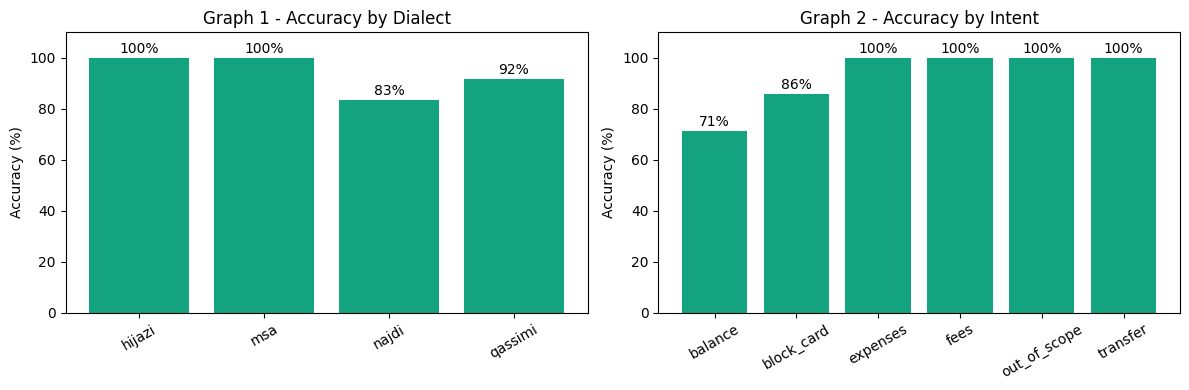

In [152]:
# Lab 6 – Code 5: Evaluation Summary and Graphs
import matplotlib.pyplot as plt
import pandas as pd

by_dialect = res.groupby("dialect")["correct"].mean() * 100
by_intent = res.groupby("intent")["correct"].mean() * 100

summary = pd.DataFrame([
    {"metric": "Overall accuracy", "value": f"{acc * 100:.1f}%"},
    {"metric": "95% CI", "value": f"{ci_low * 100:.1f}% - {ci_high * 100:.1f}%"},
    {"metric": "Test sentences", "value": str(len(res))},
    {"metric": "Errors", "value": str(int((res["correct"] == 0).sum()))},
])
print("Compact evaluation summary")
print(summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, title in [(axes[0], by_dialect, "Graph 1 - Accuracy by Dialect"),
                        (axes[1], by_intent, "Graph 2 - Accuracy by Intent")]:
    bars = ax.bar(data.index, data.values, color="#14a37f")
    ax.set_ylim(0, 110)
    ax.set_ylabel("Accuracy (%)")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
    for b, v in zip(bars, data.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 2, f"{v:.0f}%", ha="center")
plt.tight_layout()
plt.show()

In [144]:
#Demo - Code 1
!pip install -q gradio

In [145]:
#Demo code 2
import re, inspect, operator
import gradio as gr

if "predict" not in globals():
    raise NameError("شغّلي خلية التدريب أول (اللي فيها def predict)")

def _n(s):
    s = re.sub(r"[\u064B-\u0652\u0640]", "", str(s))
    s = re.sub("[أإآ]", "ا", s).replace("ى", "ي").replace("ة", "ه")
    return s.strip()

# ---------- حساب وهمي ----------
BENEFICIARIES = {
    "أبوي": ["ابوي", "والدي"],
    "أمي": ["امي", "والدتي"],
    "أخوي": ["اخوي", "اخي"],
    "محمد العتيبي": ["محمد"],
}
BEN_KEYS = {n: [_n(k) for k in ks + [n]] for n, ks in BENEFICIARIES.items()}

WORD_AMOUNTS = {
    "مية": 100, "ميه": 100, "مئة": 100, "مائة": 100,
    "مئتين": 200, "ميتين": 200, "مئتي": 200,
    "ثلاثمية": 300, "ثلاثمئة": 300, "ثلتمية": 300, "ثلاثمائة": 300,
    "اربعمية": 400, "اربعمئة": 400,
    "خمسمية": 500, "خمسمئة": 500,
    "ستمية": 600, "سبعمية": 700, "ثمانمية": 800, "تسعمية": 900,
    "الف": 1000, "الفين": 2000,
}
WORD_AMOUNTS = {_n(k): v for k, v in WORD_AMOUNTS.items()}

THRESHOLD = 0.60   # إذا ثقة النموذج أقل منه يقول "ما فهمت"

def new_state():
    return {"balance": 5000.0, "pending": None}

def extract_amount(text):
    t = _n(text).translate(str.maketrans("٠١٢٣٤٥٦٧٨٩", "0123456789"))
    m = re.search(r"\d+(?:\.\d+)?", t)
    if m:
        return float(m.group())
    for w in sorted(WORD_AMOUNTS, key=len, reverse=True):
        if w in t:
            return float(WORD_AMOUNTS[w])
    return None

def extract_beneficiary(text):
    t = _n(text)
    for name, keys in BEN_KEYS.items():
        if any(k in t for k in keys):
            return name
    return None

def process(text, state):
    state["pending"] = None
    try:
        dialect = globals()["identify"](text)
        if isinstance(dialect, (tuple, list)):
            dialect = dialect[0]
    except Exception:
        dialect = "—"
    intent, conf = predict(text)
    amount, ben = extract_amount(text), extract_beneficiary(text)

    understand = (f"**اللهجة:** {dialect}  \n**النية:** {intent} (ثقة {conf})  \n"
                  f"**المبلغ:** {amount if amount else '—'}  \n**المستفيد:** {ben if ben else '—'}")

    if operator.lt(conf, THRESHOLD):
        return understand, "ما فهمت طلبك، ممكن توضّح أكثر؟", state, False
    if intent == "balance":
        return understand, f"رصيدك الحالي: **{state['balance']:,.0f} ريال**", state, False
    if intent == "transfer":
        if amount is None:
            return understand, "كم المبلغ اللي تبي تحوّله؟", state, False
        if ben is None:
            return understand, "لمن تبي تحوّل؟ (أبوي، أمي، أخوي، محمد العتيبي)", state, False
        if operator.gt(amount, state["balance"]):
            return understand, f"الرصيد ما يكفي. رصيدك {state['balance']:,.0f} ريال.", state, False
        state["pending"] = {"amount": amount, "to": ben}
        return understand, f"تأكيد: تحويل **{amount:,.0f} ريال** إلى **{ben}**؟", state, True
    if intent == "out_of_scope":
        return understand, "هذا الطلب خارج نطاق الخدمات البنكية.", state, False
    return understand, "هذي الخدمة غير متاحة حالياً. المتاح: الرصيد والتحويل.", state, False

def confirm(state, yes):
    p = state["pending"]
    state["pending"] = None
    if not p:
        return "ما فيه عملية للتأكيد.", state
    if not yes:
        return "تم إلغاء التحويل.", state
    state["balance"] = state["balance"] - p["amount"]
    return (f"✅ تم تحويل {p['amount']:,.0f} ريال إلى {p['to']}.  \n"
            f"رصيدك الجديد: {state['balance']:,.0f} ريال"), state

# ---------- الواجهة ----------
CSS = """
.gradio-container {direction: rtl; background: linear-gradient(160deg, #f0f7f4 0%, #e3efe9 100%);}
#header {background: linear-gradient(135deg, #0b6e4f, #14a37f);
         padding: 22px 26px; border-radius: 18px; margin-bottom: 14px;
         box-shadow: 0 6px 18px rgba(11,110,79,.25);}
#header h1, #header p {color: white !important; margin: 0 0 6px 0;}
.card {background: white; border-radius: 16px; padding: 16px 20px;
       box-shadow: 0 2px 10px rgba(0,0,0,.07);}
#understand {border-right: 6px solid #0b6e4f;}
#reply {border-right: 6px solid #f4a62a; font-size: 18px;}
#send-btn {background: #0b6e4f !important; color: white !important; font-size: 17px !important;}
#yes-btn {background: #14a37f !important; color: white !important; font-size: 17px !important;}
#no-btn {background: #d64545 !important; color: white !important; font-size: 17px !important;}
textarea, input {font-size: 18px !important;}
footer {display: none !important;}
.gradio-container h3 {color: #0b3d2e !important;}
#understand, #understand *, #reply, #reply * {color: #111111 !important;}
"""

def on_send(text, state):
    u, r, state, show = process(text, state)
    return u, r, state, gr.update(visible=show), gr.update(visible=True)

def on_yes(state):
    r, state = confirm(state, True)
    return r, state, gr.update(visible=False)

def on_no(state):
    r, state = confirm(state, False)
    return r, state, gr.update(visible=False)

# يتعامل مع اختلاف نسخ Gradio (مكان css)
blocks_kw, launch_kw = {"title": "لهجتي"}, {"share": True}
if "css" in inspect.signature(gr.Blocks.launch).parameters:
    launch_kw["css"] = CSS
elif "css" in inspect.signature(gr.Blocks.__init__).parameters:
    blocks_kw["css"] = CSS

with gr.Blocks(**blocks_kw) as demo:
    gr.Markdown("# 🎙️ لهجتي\nمساعد بنكي يسمع لهجتك ويفهم طلبك ثم ينفّذه", elem_id="header")

    state = gr.State(new_state())

    with gr.Group(elem_classes="card"):
        box = gr.Textbox(label="اكتب طلبك بلهجتك", lines=2,
                         placeholder="مثال: ابي احول لأبوي خمسمية")
        gr.Examples(["وش رصيدي الحين", "ابي احول لأبوي خمسمية",
                     "أبغى أحول لأخوي مية", "ابغى احول لأمي ألف ريال"],
                    inputs=box, label="جرّب مثال")
        send = gr.Button("أرسل ➤", elem_id="send-btn")

    with gr.Column(visible=False) as results:
        gr.Markdown("### 👂 Listen & Understand")
        understand = gr.Markdown(elem_id="understand", elem_classes="card")
        gr.Markdown("### ⚙️ Execute")
        reply = gr.Markdown(elem_id="reply", elem_classes="card")

    with gr.Row(visible=False) as confirm_row:
        yes = gr.Button("✅ نعم، نفّذ", elem_id="yes-btn")
        no = gr.Button("✖ لا، إلغاء", elem_id="no-btn")

    send.click(on_send, [box, state], [understand, reply, state, confirm_row, results])
    box.submit(on_send, [box, state], [understand, reply, state, confirm_row, results])
    yes.click(on_yes, [state], [reply, state, confirm_row])
    no.click(on_no, [state], [reply, state, confirm_row])

demo.launch(**launch_kw)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://563076ebf5428f7885.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
